# Determinants and Prediction of Commercial Bank Profitability in Kenya, 2004–2015
### An econometric and machine-learning comparison on a panel of seven banks

**Question.** What drives the profitability (return on average assets, ROAA) of Kenyan commercial banks, and do machine-learning models predict it better than a conventional fixed-effects regression?

**Data.** An annual panel of seven banks (Barclays Kenya, CFC Stanbic, DTB, KCB, NBK, NIC, Standard Chartered) over 2004–2015: 84 bank-years and 12 financial ratios. The data were compiled from secondary sources: Central Bank of Kenya (CBK) Bank Supervision Annual Reports, the banks' own audited annual reports, and Nairobi Securities Exchange (NSE) publications. See `data/DATA_DICTIONARY.md`.

**Research questions**
1. Which bank-level ratios significantly explain ROAA once bank-specific differences are controlled for?
2. Do machine-learning models (ridge, random forest, XGBoost) predict ROAA better out of sample than a fixed-effects regression?
3. Can ratios reported one year flag banks that will be in distress the next year?

**Headline results**
- **Cost-to-income ratio (CIR) is the one robust driver of ROAA.** A 1-point rise in CIR is associated with about 0.24 points lower ROAA (wild-cluster-bootstrap p = 0.008), and the result holds in all six specifications tested.
- **The positive NPL coefficient is not robust.** It loses significance with few-cluster inference (p = 0.058) and disappears when the most extreme bank (NBK) is excluded. I treat it as inconclusive.
- **Machine learning does not beat the fixed-effects regression on this data.** Out-of-sample mean absolute error is 0.46 for the fixed-effects model versus 0.70 for XGBoost and 0.72 for random forest.
- **The early-warning classifier is not good enough to use** (AUC 0.68, below a "distress persists" rule at 0.74; only 6 test events). The forecasting and clustering results are similarly modest, and both are reported as such.

Everything below is reproducible from `data/bank_data.csv`. All model evaluation is **out of time** (train on the past, test on later years).

## 1. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tsa.arima.model import ARIMA
from linearmodels.panel import PanelOLS
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge, LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (r2_score, mean_absolute_error, roc_auc_score,
                             brier_score_loss, silhouette_score, adjusted_rand_score)
import xgboost as xgb, shap

SEED = 42
FIG, RES = Path("../figures"), Path("../results")
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
                     "axes.titleweight": "bold", "axes.titlesize": 11})
BANKS = ["BARCLAYS", "CFC_STANBIC", "DTB", "KCB", "NBK", "NIC", "STANCHART"]
PAL = dict(zip(BANKS, ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#7f7f7f", "#9467bd", "#8c564b"]))
FEATURES = ["CAR_%", "NPL_%", "CIR_%", "SIZE_LN_ASSETS", "LDR_%", "NIM_%", "LIQUIDITY_%"]

## 2. Data

In [2]:
df = pd.read_csv("../data/bank_data.csv").sort_values(["BANK", "YEAR"]).reset_index(drop=True)
panel = df.set_index(["BANK", "YEAR"])
print(f"{df.BANK.nunique()} banks x {df.YEAR.nunique()} years = {len(df)} bank-year observations")
df.head()

7 banks x 12 years = 84 bank-year observations


,BANK,YEAR,ROAA,ROAE,CAR_%,LDR_%,NPL_%,CIR_%,SIZE_LN_ASSETS,NIM_%,LIQUIDITY_%,Net Assets (KSh M),Advances (KSh M),Deposits (KSh M)
0,BARCLAYS,2004,5.40,61.14,13.0,76.5,13.0,54.1,11.5855,6.8,37.2,107530,63187,82583
1,BARCLAYS,2005,5.03,53.97,13.3,82.5,16.9,51.8,11.7099,7.1,38.4,121774,79516,96340
2,BARCLAYS,2006,5.83,59.34,14.7,86.8,11.2,49.2,11.8764,7.4,39.5,143826,93270,107410
3,BARCLAYS,2007,5.14,59.61,14.0,96.6,8.5,48.4,11.9699,7.8,40.2,157928,105346,109097
4,BARCLAYS,2008,4.92,54.54,15.9,85.5,12.2,50.2,12.0364,7.6,39.8,168786,108086,126408


### 2.1 Data audit

In [3]:
audit = {
    "Balanced panel (12 years for every bank)": bool((df.groupby("BANK").YEAR.count() == 12).all()),
    "Duplicate bank-year rows": int(df.duplicated(["BANK", "YEAR"]).sum()),
    "Missing values": int(df.isna().sum().sum()),
}
# Internal consistency: the ratio columns should be reproducible from the KSh columns
ldr_gap  = (df["Advances (KSh M)"] / df["Deposits (KSh M)"] * 100 - df["LDR_%"]).abs().max()
size_gap = (np.log(df["Net Assets (KSh M)"]) - df["SIZE_LN_ASSETS"]).abs().max()
audit["Max gap, LDR_% vs Advances/Deposits (pp)"] = round(float(ldr_gap), 3)
audit["Max gap, SIZE_LN_ASSETS vs ln(Net Assets)"] = round(float(size_gap), 5)
display(pd.Series(audit, name="check").to_frame())

print("Extreme observations to keep in mind (kept in the data, tested for influence later):")
display(df.loc[(df["NPL_%"] > 30) | (df.ROAA < 0), ["BANK", "YEAR", "ROAA", "NPL_%", "CIR_%"]].reset_index(drop=True))

,check
Balanced panel (12 years for every bank),True
Duplicate bank-year rows,0
Missing values,0
"Max gap, LDR_% vs Advances/Deposits (pp)",0.05
"Max gap, SIZE_LN_ASSETS vs ln(Net Assets)",0.00005


Extreme observations to keep in mind (kept in the data, tested for influence later):


,BANK,YEAR,ROAA,NPL_%,CIR_%
0,KCB,2004,1.65,37.3,72.4
1,NBK,2004,2.63,49.8,65.2
2,NBK,2005,2.72,45.0,63.4
3,NBK,2006,2.72,38.2,62.1
4,NBK,2007,4.15,33.1,58.4
5,NBK,2015,-1.36,16.1,74.6


## 3. Exploratory analysis

In [4]:
desc = df[["ROAA", "ROAE"] + FEATURES].describe().T[["mean", "std", "min", "50%", "max"]].round(2)
desc.to_csv(RES / "descriptive_statistics.csv")
desc

,mean,std,min,50%,max
ROAA,4.24,1.50,-1.36,4.36,7.39
ROAE,42.90,19.20,-49.87,44.11,90.28
CAR_%,19.10,6.66,5.00,18.10,42.60
NPL_%,8.11,9.69,0.50,4.85,49.80
CIR_%,53.93,6.97,40.80,53.50,74.60
SIZE_LN_ASSETS,11.42,0.82,9.31,11.54,13.06
LDR_%,80.42,15.54,22.60,84.80,110.10
NIM_%,7.60,1.20,4.80,7.55,9.80
LIQUIDITY_%,43.81,5.15,32.10,43.85,54.20


In [5]:
by_bank = df.groupby("BANK")[["ROAA", "ROAE", "CAR_%", "NPL_%", "CIR_%", "NIM_%", "SIZE_LN_ASSETS"]].mean().round(2).sort_values("ROAA", ascending=False)
by_bank.to_csv(RES / "bank_averages.csv")
by_bank

,ROAA,ROAE,CAR_%,NPL_%,CIR_%,NIM_%,SIZE_LN_ASSETS
BANK,,,,,,,
BARCLAYS,5.79,49.55,18.82,9.12,48.41,8.29,12.06
STANCHART,5.42,62.71,16.51,5.05,45.16,8.67,11.79
KCB,4.31,42.90,20.10,12.57,60.00,6.86,12.17
NIC,4.09,36.64,18.28,4.22,54.25,7.72,10.90
DTB,4.03,46.56,19.45,1.41,53.35,8.06,10.84
CFC_STANBIC,3.15,37.69,18.19,3.52,55.35,7.06,11.17
NBK,2.87,24.27,22.37,20.89,61.01,6.54,10.99


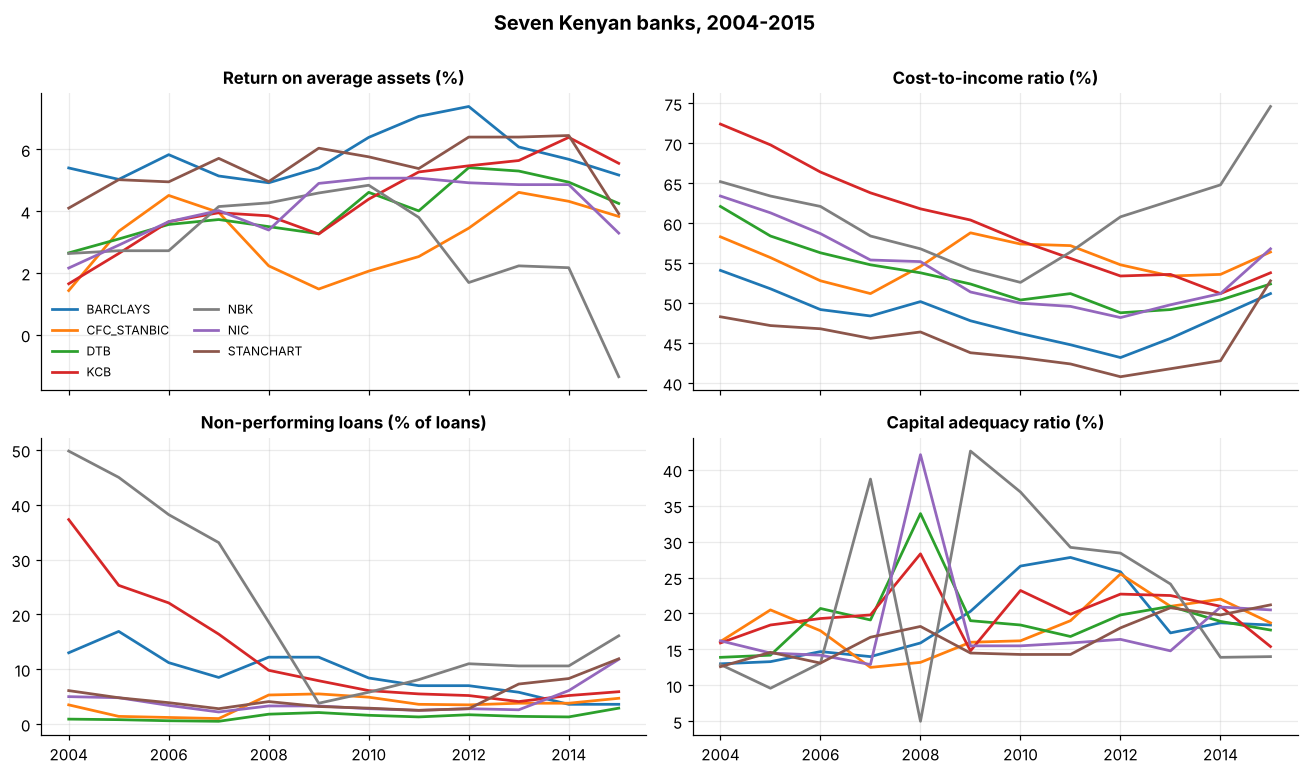

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, col, title in zip(axes.flat, ["ROAA", "CIR_%", "NPL_%", "CAR_%"],
                          ["Return on average assets (%)", "Cost-to-income ratio (%)",
                           "Non-performing loans (% of loans)", "Capital adequacy ratio (%)"]):
    for b in BANKS:
        s = panel.loc[b, col]; ax.plot(s.index, s.values, color=PAL[b], lw=1.8, label=b)
    ax.set_title(title)
axes[0, 0].legend(ncol=2, fontsize=8, frameon=False)
fig.suptitle("Seven Kenyan banks, 2004-2015", y=1.0, fontsize=13, fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "01_trends.png", bbox_inches="tight"); plt.show()

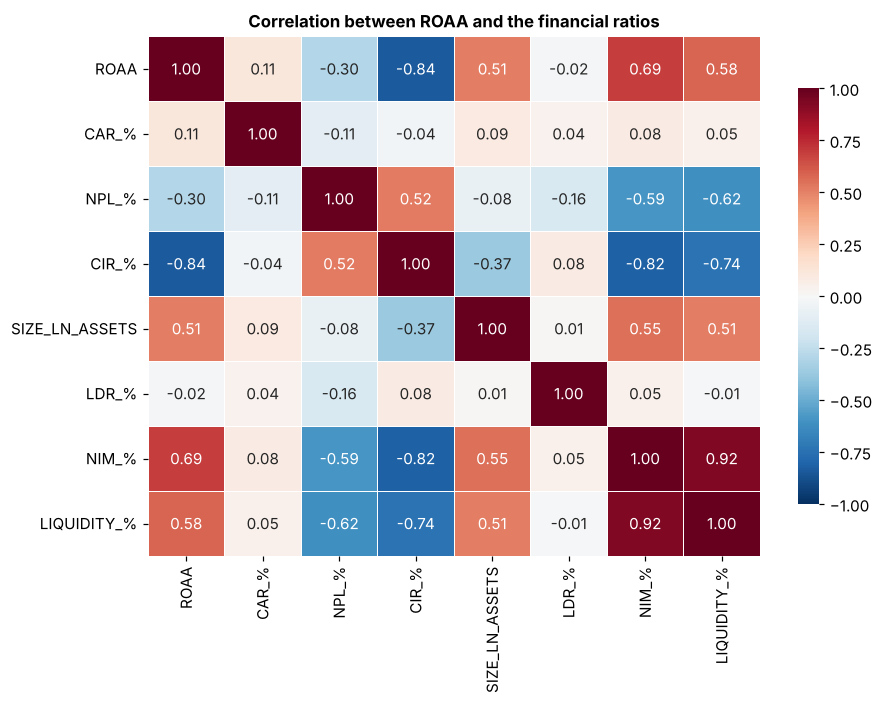

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 6.5))
corr = df[["ROAA"] + FEATURES].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax,
            cbar_kws={"shrink": .8}, linewidths=.5)
ax.set_title("Correlation between ROAA and the financial ratios"); ax.grid(False)
fig.tight_layout(); fig.savefig(FIG / "02_correlations.png", bbox_inches="tight"); plt.show()

In [8]:
Xc = sm.add_constant(df[FEATURES])
vif = pd.Series([variance_inflation_factor(Xc.values, i + 1) for i in range(len(FEATURES))],
                index=FEATURES, name="VIF").round(2)
vif.to_frame()

,VIF
CAR_%,1.03
NPL_%,2.03
CIR_%,3.34
SIZE_LN_ASSETS,1.74
LDR_%,1.16
NIM_%,10.99
LIQUIDITY_%,7.73


**What the exploratory analysis shows**
- Mean ROAA is 4.24%. Barclays (5.79%) and Standard Chartered (5.42%) are the most profitable banks and NBK (2.87%) the least; NBK posts a loss in 2015 (ROAA −1.36%).
- Cost-to-income and ROAA are strongly negatively correlated (r = −0.84), so cost efficiency is the natural first suspect.
- NPL ratios are heavily skewed: NBK (average 20.9%) and KCB in 2004 (37.3%) dominate the upper tail.
- **Multicollinearity:** NIM (VIF 11.0) and liquidity (VIF 7.7) overlap strongly with the other ratios, so their individual coefficients will be imprecise. All other VIFs are below 3.5.

## 4. Panel regression: what explains ROAA?

In [9]:
y, X = panel["ROAA"], panel[FEATURES]

def fit_fe(y, X, time_effects=False):
    m = PanelOLS(y, X, entity_effects=True, time_effects=time_effects)
    return m.fit(cov_type="clustered", cluster_entity=True), m.fit(cov_type="robust")

fe_c, fe_r = fit_fe(y, X)
fe2_c, fe2_r = fit_fe(y, X, time_effects=True)

def coef_table(res_c, res_r):
    t = pd.DataFrame({"coef": res_c.params, "se (clustered)": res_c.std_errors,
                      "p (clustered)": res_c.pvalues, "p (robust)": res_r.pvalues})
    return t.round(4)

tab_fe, tab_fe2 = coef_table(fe_c, fe_r), coef_table(fe2_c, fe2_r)
print(f"Bank fixed effects:            within R2 = {fe_c.rsquared_within:.3f}")
display(tab_fe)
print(f"Bank + year fixed effects:     within R2 = {fe2_c.rsquared_within:.3f}")
display(tab_fe2)

Bank fixed effects:            within R2 = 0.831


,coef,se (clustered),p (clustered),p (robust)
CAR_%,0.0109,0.0093,0.2451,0.2855
NPL_%,0.0314,0.0086,0.0005,0.0003
CIR_%,-0.2352,0.0262,0.0000,0.0000
SIZE_LN_ASSETS,-0.1153,0.2180,0.5985,0.6543
LDR_%,0.0059,0.0060,0.3317,0.3136
NIM_%,0.4880,0.4198,0.2490,0.0784
LIQUIDITY_%,-0.1061,0.1135,0.3533,0.2079


Bank + year fixed effects:     within R2 = 0.814


,coef,se (clustered),p (clustered),p (robust)
CAR_%,0.0163,0.0121,0.1827,0.1978
NPL_%,0.0242,0.0076,0.0024,0.0100
CIR_%,-0.2687,0.0410,0.0000,0.0000
SIZE_LN_ASSETS,-0.0609,0.2686,0.8213,0.8525
LDR_%,0.0012,0.0039,0.7569,0.8260
NIM_%,0.3704,0.2886,0.2044,0.2869
LIQUIDITY_%,-0.1318,0.0767,0.0908,0.1234


**Why fixed effects.** The seven banks are the whole population of interest (large, long-established banks), not a random sample, and unobserved bank traits such as ownership, franchise and risk culture are plausibly correlated with the ratios. Fixed effects is therefore the conceptually appropriate estimator.

**A Hausman test is not informative here.** A random-effects model needs more banks than regressors: with 7 banks and 8 parameters (7 ratios plus a constant) the between-bank regression has no residual degrees of freedom, and `linearmodels` refuses to estimate it. A Hausman statistic from this panel should not be relied on, so I do not report one.

**Inference with only seven banks.** Standard errors clustered by bank rest on 7 clusters, which is too few for the usual asymptotics. I therefore report three p-values: clustered, heteroskedasticity-robust, and a **wild cluster bootstrap with Webb weights**, the standard remedy for few clusters. The bootstrap is the most conservative and is the one to quote.

In [10]:
# With only 7 banks the clustered standard errors (7 clusters) are unreliable, so we also
# compute a wild cluster bootstrap p-value (Webb 6-point weights), which is designed for few clusters.
WEBB = np.array([-np.sqrt(1.5), -1, -np.sqrt(.5), np.sqrt(.5), 1, np.sqrt(1.5)])

def _within(a, g):
    return a - pd.DataFrame(a).groupby(g).transform("mean").values

def _tstats(Xw, yw, g, G):
    n, k = Xw.shape
    A = np.linalg.inv(Xw.T @ Xw); b = A @ Xw.T @ yw; e = yw - Xw @ b
    meat = np.zeros((k, k))
    for c in range(G):
        s = Xw[g == c].T @ e[g == c]; meat += np.outer(s, s)
    V = A @ meat @ A * (G / (G - 1)) * ((n - 1) / (n - k - G))
    return b / np.sqrt(np.diag(V))

def wild_cluster_pvalues(frame, xcols, B=4999, seed=SEED):
    rng = np.random.default_rng(seed)
    g = pd.factorize(frame.BANK)[0]; G = g.max() + 1
    Xw = _within(frame[xcols].to_numpy(float), g)
    yw = _within(frame[["ROAA"]].to_numpy(float), g).ravel()
    t_obs = _tstats(Xw, yw, g, G); out = {}
    for j, name in enumerate(xcols):
        keep = [i for i in range(len(xcols)) if i != j]          # impose H0: coef_j = 0
        fit0 = Xw[:, keep] @ np.linalg.lstsq(Xw[:, keep], yw, rcond=None)[0]
        res0 = yw - fit0
        ts = np.empty(B)
        for b in range(B):
            w = rng.choice(WEBB, size=G)[g]
            ts[b] = _tstats(Xw, fit0 + w * res0, g, G)[j]
        out[name] = (np.abs(ts) >= abs(t_obs[j])).mean()
    return pd.Series(out, name="p (wild cluster bootstrap)")

boot_p = wild_cluster_pvalues(df, FEATURES)
final = tab_fe.join(boot_p.round(4))
final.to_csv(RES / "fixed_effects_results.csv")
final

,coef,se (clustered),p (clustered),p (robust),p (wild cluster bootstrap)
CAR_%,0.0109,0.0093,0.2451,0.2855,0.2645
NPL_%,0.0314,0.0086,0.0005,0.0003,0.0578
CIR_%,-0.2352,0.0262,0.0000,0.0000,0.0076
SIZE_LN_ASSETS,-0.1153,0.2180,0.5985,0.6543,0.7213
LDR_%,0.0059,0.0060,0.3317,0.3136,0.3227
NIM_%,0.4880,0.4198,0.2490,0.0784,0.3049
LIQUIDITY_%,-0.1061,0.1135,0.3533,0.2079,0.4079


### 4.1 Robustness: which findings survive?

In [11]:
def spec(label, frame, cols=FEATURES, time_effects=False):
    f = frame.set_index(["BANK", "YEAR"])
    r = PanelOLS(f["ROAA"], f[cols], entity_effects=True, time_effects=time_effects).fit(cov_type="clustered", cluster_entity=True)
    row = {"specification": label, "n": int(r.nobs)}
    for v in ["CIR_%", "NPL_%"]:
        row[f"{v} coef"] = round(r.params[v], 3) if v in r.params else np.nan
        row[f"{v} p"]    = round(r.pvalues[v], 3) if v in r.params else np.nan
    return row

rows = [
    spec("Baseline: bank fixed effects", df),
    spec("+ year fixed effects", df, time_effects=True),
    spec("Drop NIM and LIQUIDITY (VIF > 7)", df, [c for c in FEATURES if c not in ("NIM_%", "LIQUIDITY_%")]),
    spec("Exclude NBK (most extreme NPLs)", df[df.BANK != "NBK"]),
    spec("Exclude NPL > 30%", df[df["NPL_%"] <= 30]),
    spec("2008-2015 only", df[df.YEAR >= 2008]),
]
robust = pd.DataFrame(rows)
robust.to_csv(RES / "robustness.csv", index=False)
robust

,specification,n,CIR_% coef,CIR_% p,NPL_% coef,NPL_% p
0,Baseline: bank fixed effects,84,-0.235,0.0,0.031,0.000
1,+ year fixed effects,84,-0.269,0.0,0.024,0.002
2,Drop NIM and LIQUIDITY (VIF > 7),84,-0.240,0.0,0.024,0.000
3,Exclude NBK (most extreme NPLs),72,-0.163,0.0,0.007,0.573
4,Exclude NPL > 30%,79,-0.221,0.0,0.036,0.124
5,2008-2015 only,56,-0.276,0.0,0.024,0.281


In [12]:
# Does the positive NPL coefficient reflect the raw relationship? Check within-bank correlations of NPL and ROAA.
within_corr = df.groupby("BANK").apply(lambda g: g["ROAA"].corr(g["NPL_%"])).round(2).rename("corr(ROAA, NPL)")
within_corr.to_frame().T

BANK,BARCLAYS,CFC_STANBIC,DTB,KCB,NBK,NIC,STANCHART
"corr(ROAA, NPL)",-0.4,-0.53,0.29,-0.85,-0.09,-0.41,-0.36


In [13]:
# Standardised effect sizes: coefficient x within-bank standard deviation of each ratio (ROAA points per 1 SD move)
within_sd = (panel[FEATURES] - panel[FEATURES].groupby("BANK").transform("mean")).std()
effect = (tab_fe["coef"] * within_sd).rename("ROAA change per 1 within-bank SD").round(3)
pd.concat([within_sd.rename("within-bank SD").round(2), effect], axis=1)

,within-bank SD,ROAA change per 1 within-bank SD
CAR_%,6.44,0.070
NPL_%,7.36,0.231
CIR_%,4.48,-1.055
SIZE_LN_ASSETS,0.63,-0.073
LDR_%,11.24,0.066
NIM_%,0.94,0.457
LIQUIDITY_%,3.83,-0.406


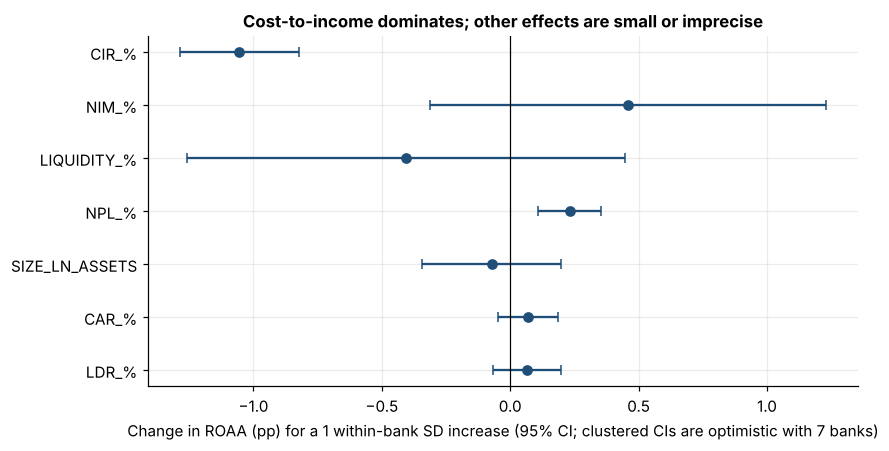

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.2))
est = tab_fe["coef"]; ci = 1.96 * tab_fe["se (clustered)"]
# standardise so the bars are comparable across ratios
est_s, ci_s = est * within_sd, ci * within_sd
order = est_s.abs().sort_values().index
ax.errorbar(est_s[order], range(len(order)), xerr=ci_s[order], fmt="o", color="#1f4e79", capsize=3)
ax.axvline(0, color="k", lw=.8); ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
ax.set_xlabel("Change in ROAA (pp) for a 1 within-bank SD increase (95% CI; clustered CIs are optimistic with 7 banks)")
ax.set_title("Cost-to-income dominates; other effects are small or imprecise"); fig.tight_layout()
fig.savefig(FIG / "03_fe_effects.png", bbox_inches="tight"); plt.show()

**Reading the regression results**
- **Cost-to-income ratio is robust.** The coefficient is −0.24 (bank fixed effects) to −0.27 (adding year effects), significant in every specification, with a wild-bootstrap p-value of 0.008. A one within-bank standard deviation increase in CIR (4.5 points) is associated with about 1.1 points lower ROAA, far larger than any other ratio.
- **NPL is not robust.** The coefficient is positive, the opposite of what theory predicts for bad loans. With few-cluster inference it is borderline (bootstrap p = 0.058), and it is not significant when NBK is excluded (p = 0.57), when only 2008–2015 is used (p = 0.28) or when NPL ratios above 30% are dropped (p = 0.12). In the raw data, ROAA and NPL are negatively correlated within six of the seven banks. The positive sign is therefore best read as a statistical artefact of a few extreme observations, not as evidence that bad loans raise profit.
- **CAR, size, loan-to-deposit, NIM and liquidity are not significant.** NIM and liquidity are collinear (VIF 11.0 and 7.7), so their separate effects cannot be pinned down; bank size varies little *within* a bank (SD 0.63 log points), which limits what a fixed-effects model can say about scale economies.
- Year effects change the coefficients only slightly, so the CIR finding is not an artefact of common shocks such as the 2007–08 period.

## 5. Does machine learning predict profitability better?

Each model is evaluated with an **expanding-window, out-of-time design**: for each test year *t* from 2010 to 2015, models are trained on all years before *t* and asked to estimate ROAA for that year from its same-year ratios. That gives 42 out-of-sample predictions (7 banks × 6 years). This asks "given a bank's ratios, how well can each model estimate its ROAA in years it has not seen?", which is an explanatory test, not a forecast of future ratios.

Models compared:
- **Baselines:** last year's ROAA (naive) and each bank's historical average.
- **Fixed-effects regression:** OLS with the seven ratios plus a dummy for each bank, matching section 4.
- **Machine learning:** ridge regression, random forest and XGBoost on the seven ratios.

Hyperparameters are fixed in advance and not tuned: with 84 observations, tuning on the test years would overstate performance.

In [15]:
def make_models():
    return {
        "Ridge":        make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        "Random forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=SEED),
        "XGBoost":      xgb.XGBRegressor(n_estimators=200, max_depth=3, learning_rate=.05, subsample=.8, random_state=SEED),
    }

d = df.copy(); d["ROAA_lag"] = d.groupby("BANK").ROAA.shift(1)
folds = []
for t in range(2010, 2016):                      # expanding window: train on years < t, test on year t
    tr, te = d[d.YEAR < t], d[d.YEAR == t]
    out = pd.DataFrame({"BANK": te.BANK.values, "YEAR": t, "actual": te.ROAA.values})
    out["Naive: last year's ROAA"] = te.ROAA_lag.values
    out["Bank average (training years)"] = te.BANK.map(tr.groupby("BANK").ROAA.mean()).values
    dummies = pd.get_dummies(tr.BANK, dtype=float)
    Xtr = pd.concat([tr[FEATURES].reset_index(drop=True), dummies.reset_index(drop=True)], axis=1)
    Xte = pd.concat([te[FEATURES].reset_index(drop=True),
                     pd.get_dummies(te.BANK, dtype=float).reindex(columns=dummies.columns, fill_value=0).reset_index(drop=True)], axis=1)
    out["Fixed-effects regression"] = LinearRegression(fit_intercept=False).fit(Xtr, tr.ROAA).predict(Xte[Xtr.columns])
    for name, m in make_models().items():
        out[name] = m.fit(tr[FEATURES], tr.ROAA).predict(te[FEATURES])
    folds.append(out)
pred = pd.concat(folds, ignore_index=True)
models_cols = [c for c in pred.columns if c not in ("BANK", "YEAR", "actual")]

score = pd.DataFrame({
    "R2":   {m: r2_score(pred.actual, pred[m]) for m in models_cols},
    "MAE":  {m: mean_absolute_error(pred.actual, pred[m]) for m in models_cols},
    "RMSE": {m: np.sqrt(((pred.actual - pred[m]) ** 2).mean()) for m in models_cols},
}).sort_values("MAE").round(3)
score.to_csv(RES / "model_comparison.csv")
print(f"{len(pred)} out-of-sample predictions (7 banks x test years 2010-2015)")
score

42 out-of-sample predictions (7 banks x test years 2010-2015)


,R2,MAE,RMSE
Fixed-effects regression,0.854,0.461,0.625
Ridge,0.729,0.607,0.852
XGBoost,0.620,0.697,1.009
Random forest,0.627,0.715,1.000
Naive: last year's ROAA,0.614,0.722,1.017
Bank average (training years),0.225,1.212,1.441


In [16]:
# Is the gap between the best model and the ML models more than noise? Paired Wilcoxon test on absolute errors.
err = {m: (pred.actual - pred[m]).abs() for m in models_cols}
rows = []
for m in ["XGBoost", "Random forest", "Ridge", "Naive: last year's ROAA"]:
    w = stats.wilcoxon(err["Fixed-effects regression"], err[m])
    rows.append({"compared with": m, "MAE difference (model - FE)": round((err[m] - err["Fixed-effects regression"]).mean(), 3),
                 "Wilcoxon p": round(w.pvalue, 4)})
pd.DataFrame(rows)

,compared with,MAE difference (model - FE),Wilcoxon p
0,XGBoost,0.236,0.0250
1,Random forest,0.254,0.0164
2,Ridge,0.145,0.1158
3,Naive: last year's ROAA,0.261,0.0489


**Fairness check.** The fixed-effects model is told which bank it is predicting for, while the tree models above were not. Giving them bank indicators narrows the gap only slightly (XGBoost MAE 0.70 → 0.65, random forest 0.72 → 0.70), and both remain well behind the fixed-effects model (0.46). The conclusion does not depend on this asymmetry.

In [17]:
# Fairness check: the fixed-effects model knows which bank it is predicting for. Give the tree models the same information.
Dm = pd.concat([df, pd.get_dummies(df.BANK, dtype=float)], axis=1); bank_cols = list(pd.get_dummies(df.BANK).columns)
rows = []
for name, mk in [("XGBoost", lambda: make_models()["XGBoost"]), ("Random forest", lambda: make_models()["Random forest"])]:
    for label, cols in [("ratios only", FEATURES), ("ratios + bank indicators", FEATURES + bank_cols)]:
        P, Y = [], []
        for t in range(2010, 2016):
            tr, te = Dm[Dm.YEAR < t], Dm[Dm.YEAR == t]
            P += list(mk().fit(tr[cols], tr.ROAA).predict(te[cols])); Y += list(te.ROAA)
        rows.append({"model": name, "inputs": label, "R2": round(r2_score(Y, P), 3), "MAE": round(mean_absolute_error(Y, P), 3)})
pd.DataFrame(rows)

,model,inputs,R2,MAE
0,XGBoost,ratios only,0.620,0.697
1,XGBoost,ratios + bank indicators,0.654,0.651
2,Random forest,ratios only,0.627,0.715
3,Random forest,ratios + bank indicators,0.647,0.695


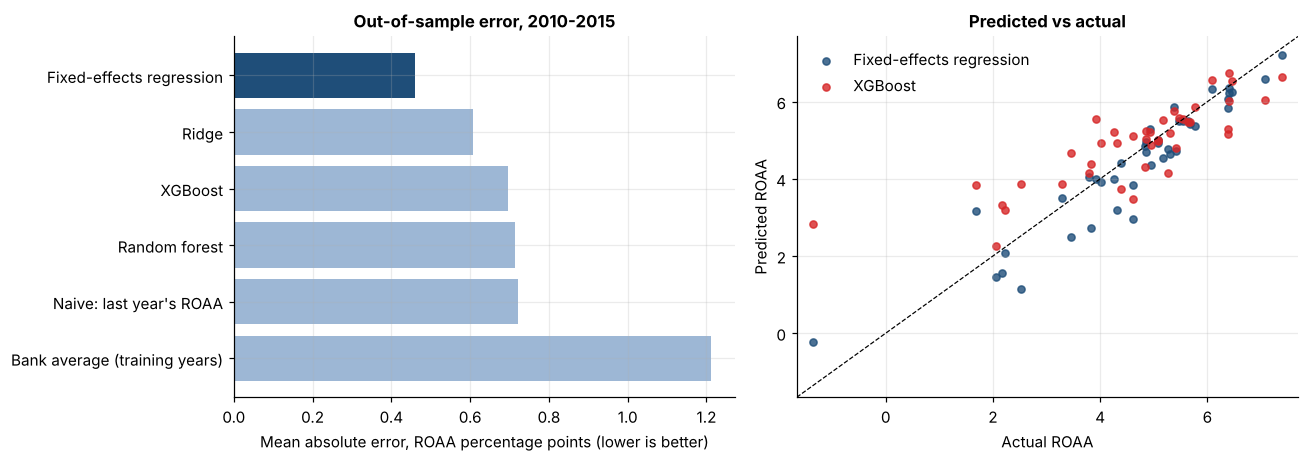

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
order = score.sort_values("MAE", ascending=False).index
axes[0].barh(order, score.loc[order, "MAE"], color=["#1f4e79" if o == "Fixed-effects regression" else "#9db7d5" for o in order])
axes[0].set_xlabel("Mean absolute error, ROAA percentage points (lower is better)"); axes[0].set_title("Out-of-sample error, 2010-2015")
for m, c in [("Fixed-effects regression", "#1f4e79"), ("XGBoost", "#d62728")]:
    axes[1].scatter(pred.actual, pred[m], s=22, alpha=.8, color=c, label=m)
lim = [pred.actual.min() - .3, pred.actual.max() + .3]
axes[1].plot(lim, lim, "k--", lw=.8); axes[1].set_xlim(lim); axes[1].set_ylim(lim)
axes[1].set_xlabel("Actual ROAA"); axes[1].set_ylabel("Predicted ROAA"); axes[1].set_title("Predicted vs actual"); axes[1].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "04_model_comparison.png", bbox_inches="tight"); plt.show()

### 5.1 What does the flexible model rely on?

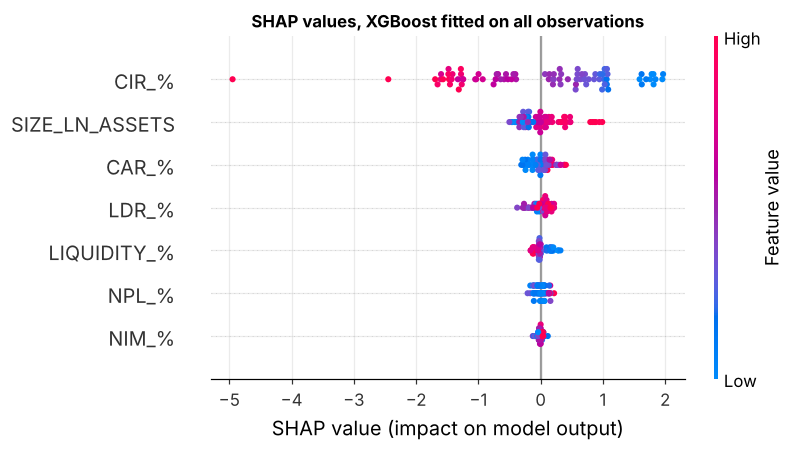

,XGBoost share of mean |SHAP|,Fixed-effects share of |standardised effect|
CIR_%,0.608,0.447
SIZE_LN_ASSETS,0.154,0.031
CAR_%,0.074,0.030
LDR_%,0.062,0.028
LIQUIDITY_%,0.047,0.172
NPL_%,0.040,0.098
NIM_%,0.016,0.194


In [19]:
# Explanatory use: fit XGBoost on all 84 observations and explain it with SHAP.
xgb_full = xgb.XGBRegressor(n_estimators=200, max_depth=3, learning_rate=.05, subsample=.8, random_state=SEED).fit(df[FEATURES], df.ROAA)
sv = shap.TreeExplainer(xgb_full).shap_values(df[FEATURES])
shap_imp = pd.Series(np.abs(sv).mean(0), index=FEATURES, name="mean |SHAP|").sort_values(ascending=False)

plt.figure(figsize=(7.5, 4.2)); shap.summary_plot(sv, df[FEATURES], show=False, plot_size=None)
plt.title("SHAP values, XGBoost fitted on all observations"); plt.tight_layout()
plt.savefig(FIG / "05_shap.png", bbox_inches="tight"); plt.show()

cmp = pd.concat([(shap_imp / shap_imp.sum()).rename("XGBoost share of mean |SHAP|"),
                 (effect.abs() / effect.abs().sum()).rename("Fixed-effects share of |standardised effect|")], axis=1).round(3)
cmp.sort_values("XGBoost share of mean |SHAP|", ascending=False)

**What this shows**
- **The fixed-effects regression is the most accurate model** (R² 0.85, MAE 0.46 percentage points). Its advantage over XGBoost and random forest is statistically distinguishable on paired absolute errors (Wilcoxon p = 0.025 and 0.016); its advantage over ridge (p = 0.12) is not.
- On 84 observations with seven predictors, there is not enough data for flexible models to find structure that a linear model with bank effects misses. The relationship between ROAA and cost efficiency is close to linear, which also favours the simpler model.
- **SHAP** (a descriptive fit on all observations) agrees on the main driver: CIR accounts for 61% of XGBoost's importance, against 45% of the standardised fixed-effects effects. It differs on **bank size**: 15% of XGBoost importance versus 3% in the regression. A tree model has no bank identifier, and size separates large banks from small ones, so its SHAP importance is likely to reflect between-bank differences, not scale economies. The regression, which removes those differences, finds no within-bank size effect.

## 6. Peer groups of banks

In [20]:
profile = df.groupby("BANK")[["ROAA", "ROAE"] + FEATURES].mean()
Z = StandardScaler().fit_transform(profile)

sil = {k: silhouette_score(Z, KMeans(k, n_init=50, random_state=SEED).fit_predict(Z)) for k in (2, 3, 4)}
print("Silhouette by number of clusters (0.5+ = clear structure, below 0.25 = weak):", {k: round(v, 2) for k, v in sil.items()})

# Do the groups change if we change the features used? (Seven banks cannot support firm conclusions.)
specs = {
    "Ratios + ROAA/ROAE": ["ROAA", "ROAE"] + FEATURES,
    "Ratios only":        FEATURES,
    "All 12 original columns": [c for c in df.columns if c not in ("BANK", "YEAR")],
}
assign = {}
for label, cols in specs.items():
    Zs = StandardScaler().fit_transform(df.groupby("BANK")[cols].mean())
    assign[label] = KMeans(3, n_init=50, random_state=SEED).fit_predict(Zs)
assign = pd.DataFrame(assign, index=profile.index)
base = assign.iloc[:, 0]
print("Agreement with the main solution (adjusted Rand index, 1 = identical):",
      {c: round(adjusted_rand_score(base, assign[c]), 2) for c in assign})
assign

Silhouette by number of clusters (0.5+ = clear structure, below 0.25 = weak): {2: 0.27, 3: 0.27, 4: 0.21}
Agreement with the main solution (adjusted Rand index, 1 = identical): {'Ratios + ROAA/ROAE': 1.0, 'Ratios only': 0.54, 'All 12 original columns': 0.63}


,Ratios + ROAA/ROAE,Ratios only,All 12 original columns
BANK,,,
BARCLAYS,0,1,2
CFC_STANBIC,2,1,0
DTB,2,1,0
KCB,1,0,2
NBK,1,0,1
NIC,2,1,0
STANCHART,0,2,2


,ROAA,ROAE,CAR_%,NPL_%,CIR_%,SIZE_LN_ASSETS,LDR_%,NIM_%,LIQUIDITY_%,banks
cluster,,,,,,,,,,
0,5.61,56.13,17.66,7.08,46.78,11.92,70.64,8.48,46.25,"BARCLAYS, STANCHART"
1,3.59,33.58,21.23,16.73,60.50,11.58,78.95,6.70,40.12,"KCB, NBK"
2,3.76,40.30,18.64,3.05,54.32,10.97,87.93,7.61,44.65,"CFC_STANBIC, DTB, NIC"


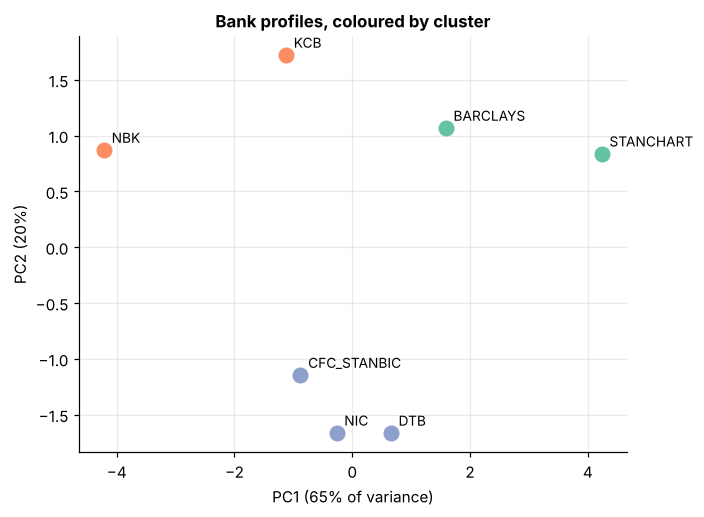

In [21]:
profile["cluster"] = KMeans(3, n_init=50, random_state=SEED).fit_predict(Z)
profile[["cluster"]].to_csv(RES / "bank_clusters.csv")
display(profile.groupby("cluster").mean().round(2).assign(banks=profile.groupby("cluster").apply(lambda g: ", ".join(g.index))))

pc = PCA(2, random_state=SEED).fit(Z); P = pc.transform(Z)
fig, ax = plt.subplots(figsize=(6.5, 4.8))
for i, b in enumerate(profile.index):
    ax.scatter(*P[i], s=90, color=plt.cm.Set2(profile.cluster.iloc[i])); ax.annotate(b, P[i], xytext=(5, 5), textcoords="offset points", fontsize=9)
ax.set_xlabel(f"PC1 ({pc.explained_variance_ratio_[0]:.0%} of variance)"); ax.set_ylabel(f"PC2 ({pc.explained_variance_ratio_[1]:.0%})")
ax.set_title("Bank profiles, coloured by cluster"); fig.tight_layout()
fig.savefig(FIG / "06_clusters.png", bbox_inches="tight"); plt.show()

**Reading the clusters.** Three peer groups emerge on the main specification: **high-profit, low-cost** (Barclays, Standard Chartered), **high-NPL, high-cost** (KCB, NBK) and **middle** (CFC Stanbic, DTB, NIC).

**These groups are descriptive, not a finding.** The silhouette score is only 0.27 (clear structure would be 0.5 or above), and the assignment changes when the feature set changes (adjusted Rand index of 0.54 and 0.63 against the main solution). With seven banks, k-means cannot support firm segmentation; I use it only to summarise how the banks differ.

## 7. Early-warning classifier

**Design.** A bank-year is labelled *distressed* if NPL exceeds 10% or ROAA is below 1%. These thresholds are my own choice, not regulatory definitions. The classifier uses the ratios reported in year *t* (including ROAA) to predict whether the bank is distressed in year *t+1*. Using a *future* label means the classifier cannot trivially see the outcome in its inputs. It is evaluated out of time, as in section 5, against two benchmarks: assuming "distressed now means distressed next year", and a constant base rate.

In [22]:
d = df.copy()
d["distress"] = ((d["NPL_%"] > 10) | (d.ROAA < 1)).astype(int)
d["distress_next"] = d.groupby("BANK").distress.shift(-1)
ds = d.dropna(subset=["distress_next"])
feats = FEATURES + ["ROAA"]

print("Distress bank-years by year:", d.groupby("YEAR").distress.sum().to_dict())
parts = []
for t in range(2009, 2015):                 # train on feature-years < t, predict distress in year t+1
    tr, te = ds[ds.YEAR < t], ds[ds.YEAR == t]
    m = make_pipeline(StandardScaler(), LogisticRegression(C=.5, max_iter=1000)).fit(tr[feats], tr.distress_next)
    parts.append(pd.DataFrame({"y": te.distress_next.values, "model": m.predict_proba(te[feats])[:, 1], "persistence": te.distress.values}))
ew = pd.concat(parts)
base_rate = ew.y.mean()
ews = pd.DataFrame({
    "AUC": {"Logistic regression": roc_auc_score(ew.y, ew.model), "Persistence (distress now = distress next year)": roc_auc_score(ew.y, ew.persistence)},
    "Brier score": {"Logistic regression": brier_score_loss(ew.y, ew.model), "Persistence (distress now = distress next year)": brier_score_loss(ew.y, ew.persistence)},
}).round(3)
ews.loc["Constant base rate", ["AUC", "Brier score"]] = [0.5, round(brier_score_loss(ew.y, np.full(len(ew), base_rate)), 3)]
ews.to_csv(RES / "early_warning.csv")
print(f"{len(ew)} out-of-sample predictions, of which only {int(ew.y.sum())} are distress events")
ews

Distress bank-years by year: {2004: 3, 2005: 3, 2006: 3, 2007: 2, 2008: 2, 2009: 1, 2010: 0, 2011: 0, 2012: 1, 2013: 1, 2014: 1, 2015: 3}
42 out-of-sample predictions, of which only 6 are distress events


,AUC,Brier score
Logistic regression,0.681,0.117
Persistence (distress now = distress next year),0.736,0.095
Constant base rate,0.500,0.122


**This classifier is not reliable enough to use.** Its AUC (0.68) is *below* the persistence rule (0.74), and its Brier score (0.117) is barely better than predicting the base rate (0.122). Only 6 of the 42 test cases are distress events, so any performance figure here is highly uncertain. The data show that distress is persistent (concentrated in 2004–2008 and in 2015), but they cannot support an early-warning claim.

## 8. Forecasting ROAA

In [23]:
fc_rows = []
for b, g in df.groupby("BANK"):
    s = g.set_index("YEAR").ROAA
    for t in range(2010, 2016):                     # one-step-ahead, expanding window
        h = s[s.index < t].to_numpy()
        row = {"BANK": b, "YEAR": t, "actual": s[t], "Naive (last value)": h[-1], "Historical mean": h.mean()}
        for name, order, trend in [("AR(1)", (1, 0, 0), "c"), ("ARIMA(1,1,0)", (1, 1, 0), "n")]:
            row[name] = ARIMA(h, order=order, trend=trend).fit().forecast(1)[0]
        fc_rows.append(row)
fc = pd.DataFrame(fc_rows)
fcols = [c for c in fc.columns if c not in ("BANK", "YEAR", "actual")]
fc_score = pd.DataFrame({"MAE": {m: (fc.actual - fc[m]).abs().mean() for m in fcols},
                         "RMSE": {m: np.sqrt(((fc.actual - fc[m]) ** 2).mean()) for m in fcols}}).sort_values("MAE").round(3)
fc_score.to_csv(RES / "forecast_comparison.csv")
print(f"{len(fc)} one-step-ahead forecasts")
fc_score

42 one-step-ahead forecasts


,MAE,RMSE
Naive (last value),0.722,1.017
"ARIMA(1,1,0)",0.806,1.081
AR(1),0.845,1.114
Historical mean,1.212,1.441


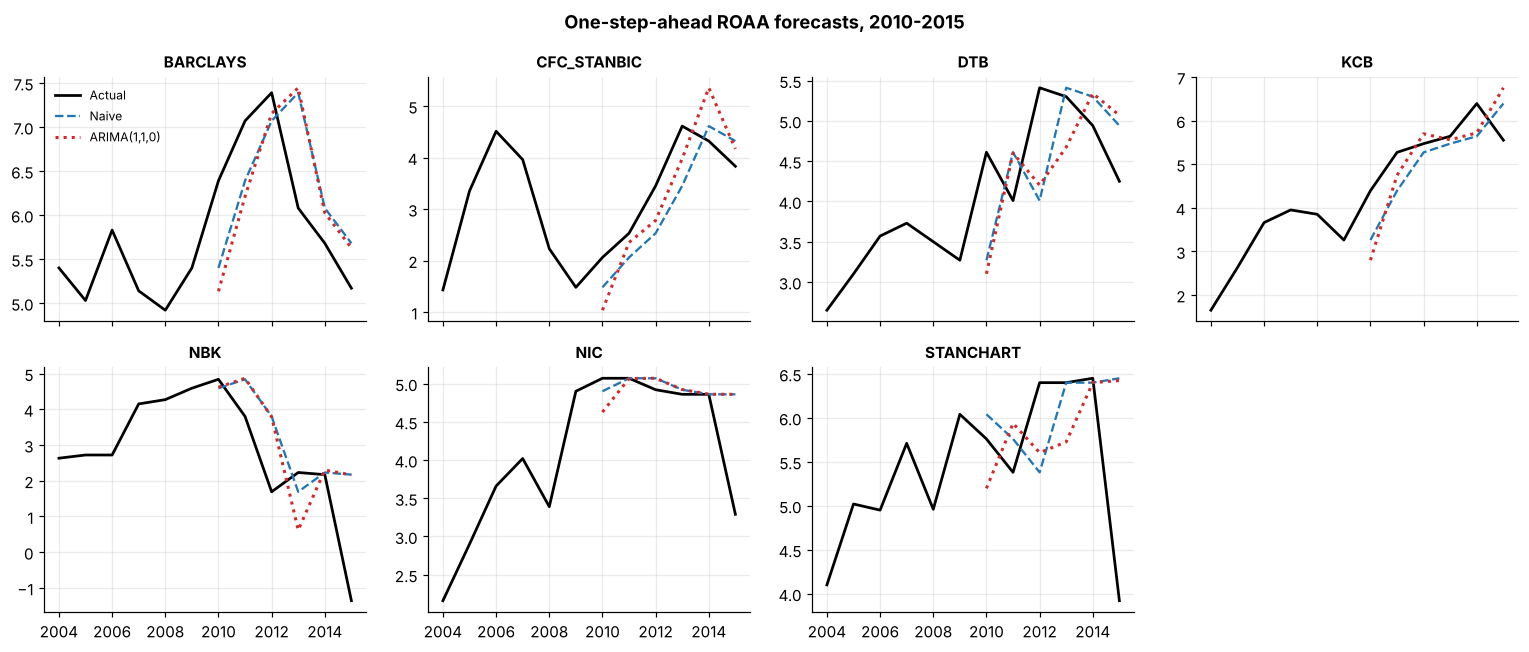

In [24]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex=True)
for ax, b in zip(axes.flat, BANKS):
    s = df[df.BANK == b].set_index("YEAR").ROAA; f = fc[fc.BANK == b].set_index("YEAR")
    ax.plot(s.index, s.values, color="k", lw=1.8, label="Actual")
    ax.plot(f.index, f["Naive (last value)"], "--", color="#1f77b4", label="Naive")
    ax.plot(f.index, f["ARIMA(1,1,0)"], ":", color="#d62728", lw=2, label="ARIMA(1,1,0)")
    ax.set_title(b, fontsize=10)
axes.flat[-1].axis("off"); axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle("One-step-ahead ROAA forecasts, 2010-2015", fontweight="bold"); fig.tight_layout()
fig.savefig(FIG / "07_forecasts.png", bbox_inches="tight"); plt.show()

**Simple beats complex.** Repeating last year's ROAA (MAE 0.72) beats both ARIMA specifications (0.81 and 0.85) and the historical mean (1.21). Each bank has only 6–11 annual observations at each forecast origin, too few to estimate time-series models reliably. I therefore do not project beyond 2015: there is no evidence that any model improves on "next year looks like this year".

## 9. Conclusions

1. **Cost efficiency is what separates profitable from less profitable Kenyan banks in this sample.** CIR is the only ratio with a large, stable, statistically robust relationship to ROAA across estimators, subsamples and inference methods.
2. **The NPL result should not be interpreted causally.** The positive coefficient is sensitive to a few extreme observations and conflicts with the within-bank raw correlations.
3. **Conventional econometrics beats machine learning here.** With 7 banks and 84 observations, a fixed-effects regression predicts out of sample better than ridge, random forest or XGBoost. The practical lesson is to benchmark flexible models against a strong simple baseline, and to evaluate out of time.
4. **Early-warning and forecasting claims are not supported** by data of this size.

**Implication for supervisors and analysts:** monitoring cost-to-income trends is likely to be more informative about profitability than the other ratios available in public reports; a larger bank panel (including the smaller banks, or quarterly data) would be needed to build predictive tools.

## 10. Limitations

- **Small sample.** Seven banks and 84 observations; asymptotic results are approximate, and many tests have low power.
- **Selection.** The seven banks are among the larger, long-established banks, so the results may not generalise to small or newer banks.
- **Association, not causation.** Cost-to-income and ROAA are both functions of income and expenses, so part of their relationship is mechanical; the regression does not identify a causal effect.
- **Period.** 2004–2015 is before the 2016 interest-rate cap and later regulatory changes.
- **Data provenance.** The data are compiled secondary data. I verified internal consistency (loan-to-deposit ratio and log-assets reproduce from the KSh columns to within rounding; the panel is balanced with no gaps) but did not re-verify each figure against the source reports.
- **Researcher choices.** The distress thresholds, model hyperparameters and cluster features are fixed, documented choices; results may change under different ones.